# 02 — Détection d'anomalies : Random Forest

**Responsable : Membre 2** · Cible : `label` (0 = normal, 1 = anomalie) · Entrée : `data/processed/*` (notebook 01)

## Workflow
1. Chargement des splits et définition du pipeline (`prétraitement → [rééchantillonnage] → Random Forest`)
2. **Baseline** (hyper-paramètres par défaut)
3. **Comparaison des stratégies d'équilibrage** en validation croisée (train uniquement)
4. **Réglage des hyper-paramètres** (`RandomizedSearchCV`, CV stratifiée)
5. Courbe d'apprentissage et contrôle du surapprentissage
6. Évaluation en validation : rapport, matrice de confusion, ROC / PR
7. **Calibration** : (a) du **seuil de décision** (b) des **probabilités** (Platt / isotonique) — sur la validation
8. **Évaluation finale unique sur le test**
9. Interprétation (importances, permutation) et analyse des erreurs par type d'attaque
10. Sauvegarde du modèle et des résultats pour le tableau comparatif (notebook 06)

> Métrique principale : **F1** et **PR-AUC** (classe positive = anomalie), plus **FPR / FNR** car une fausse alerte et une attaque manquée
> n'ont pas le même coût. L'accuracy seule est trompeuse quand les classes sont déséquilibrées.

In [1]:
import sys, time, warnings
sys.path.append("../src")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
import ml_utils as U
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_validate, learning_curve
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.4f}".format); pd.set_option("display.max_columns", 40)
RS = U.RANDOM_STATE
cfg = U.load_config(); NUM, CAT = cfg["numeric_cols"], cfg["categorical_cols"]
X_train, y_tr = U.load_split("train"); X_valid, y_va = U.load_split("valid"); X_test, y_te = U.load_split("test")
ytr, yva, yte = y_tr["label"].to_numpy(), y_va["label"].to_numpy(), y_te["label"].to_numpy()
print({"train": X_train.shape, "valid": X_valid.shape, "test": X_test.shape})
print("Part d'anomalies (train/valid/test) :", ytr.mean().round(4), yva.mean().round(4), yte.mean().round(4))

{'train': (110132, 33), 'valid': (36711, 33), 'test': (36711, 33)}
Part d'anomalies (train/valid/test) : 0.7715 0.7715 0.7715


## 1. Pipeline

Le pipeline regroupe prétraitement, rééchantillonnage et modèle : en validation croisée, **tout est ré-appris sur chaque pli d'apprentissage**
et le rééchantillonnage n'est jamais appliqué au pli de validation. Un Random Forest n'a pas besoin de standardisation (`scale=False`).

In [2]:
SAMPLERS = {
    "Aucun": lambda: None,
    "class_weight": lambda: None,
    "Sous-échantillonnage": lambda: RandomUnderSampler(random_state=RS),
    "Sur-échantillonnage": lambda: RandomOverSampler(random_state=RS),
    "SMOTE": lambda: SMOTE(k_neighbors=5, random_state=RS),
}
def make_pipe(strategy="class_weight", **rf_params):
    steps = [("pre", U.make_preprocessor(NUM, CAT, scale=False))]
    sampler = SAMPLERS[strategy]()
    if sampler is not None: steps.append(("sampler", sampler))
    rf_kw = dict(n_jobs=-1, random_state=RS, class_weight="balanced_subsample" if strategy == "class_weight" else None)
    rf_kw.update(rf_params)
    steps.append(("rf", RandomForestClassifier(**rf_kw)))
    return ImbPipeline(steps)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
sub = X_train.sample(50000, random_state=RS).index          # sous-échantillon pour accélérer la CV / le réglage
Xs, ys = X_train.loc[sub], ytr[sub]
make_pipe()

,steps,"[('pre', ...), ('rf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_log', ...), ('num_lin', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_wei

## 2. Baseline
Random Forest par défaut (100 arbres, sans équilibrage), évalué en validation.

In [3]:
t0 = time.time(); base = make_pipe("Aucun", n_estimators=100).fit(X_train, ytr); t_base = time.time() - t0
p_base = base.predict_proba(X_valid)[:, 1]
base_valid = U.binary_metrics(yva, (p_base >= .5).astype(int), scores=p_base, proba=p_base)
print(f"Temps d'entraînement : {t_base:.1f}s"); display(pd.Series(base_valid).to_frame("baseline (validation)").T.round(4))

Temps d'entraînement : 10.2s


,accuracy,balanced_accuracy,precision,recall,f1,mcc,tn,fp,fn,tp,fpr,fnr,roc_auc,pr_auc,brier
baseline (validation),0.9983,0.9974,0.9987,0.9990,0.9989,0.9951,8351.0000,36.0000,28.0000,28296.0000,0.0043,0.0010,0.9999,0.9999,0.0014


## 3. Choix de la stratégie d'équilibrage

Validation croisée stratifiée à 3 plis sur le train (sous-échantillon de 50 000 lignes). Le rééchantillonnage est refait dans chaque pli.
La stratégie est choisie sur le **F1 macro** (les deux classes comptent autant) et la **PR-AUC**, jamais sur le test.

,f1_macro,balanced_acc,pr_auc,recall,precision,std_f1_macro,temps_s
stratégie,,,,,,,
Aucun,0.9971,0.9969,1.0000,0.9988,0.9985,0.0006,8.8920
class_weight,0.9971,0.9967,1.0000,0.9990,0.9983,0.0007,8.8746
Sous-échantillonnage,0.9956,0.9970,0.9999,0.9969,0.9991,0.0005,6.2960
Sur-échantillonnage,0.9974,0.9974,1.0000,0.9987,0.9989,0.0003,11.3501
SMOTE,0.9973,0.9973,1.0000,0.9987,0.9988,0.0004,14.2349



=> Stratégie retenue (meilleur F1 macro en CV) : Sur-échantillonnage


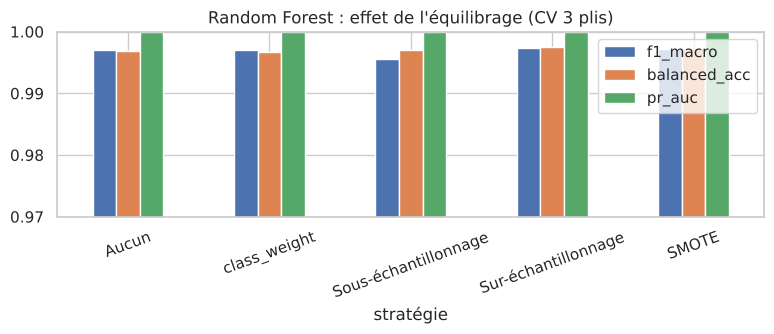

In [4]:
rows = []
for name in SAMPLERS:
    t0 = time.time()
    r = cross_validate(make_pipe(name, n_estimators=100), Xs, ys, cv=cv, n_jobs=1,
                       scoring={"f1_macro": "f1_macro", "balanced_acc": "balanced_accuracy", "pr_auc": "average_precision", "recall": "recall", "precision": "precision"})
    rows.append({"stratégie": name, **{k.replace("test_", ""): v.mean() for k, v in r.items() if k.startswith("test_")},
                 "std_f1_macro": r["test_f1_macro"].std(), "temps_s": time.time() - t0})
bal = pd.DataFrame(rows).set_index("stratégie"); display(bal.round(4))
best_strategy = bal["f1_macro"].idxmax(); print(f"\n=> Stratégie retenue (meilleur F1 macro en CV) : {best_strategy}")
fig, ax = plt.subplots(figsize=(8, 3.5)); bal[["f1_macro", "balanced_acc", "pr_auc"]].plot(kind="bar", ax=ax); ax.set_ylim(.97, 1.0)
ax.set_title("Random Forest : effet de l'équilibrage (CV 3 plis)"); ax.tick_params(axis="x", rotation=20); plt.tight_layout(); U.savefig(fig, "02_balancing_cv"); plt.show()

## 4. Réglage des hyper-paramètres

`RandomizedSearchCV` (15 combinaisons × 3 plis) avec la stratégie d'équilibrage retenue. Les hyper-paramètres qui contrôlent la complexité
(`max_depth`, `min_samples_leaf`, `max_features`) limitent le surapprentissage ; `n_estimators` réduit la variance.

In [5]:
param_dist = {"rf__n_estimators": [100, 200, 300], "rf__max_depth": [None, 12, 20, 30], "rf__min_samples_leaf": [1, 2, 4, 8],
              "rf__min_samples_split": [2, 5, 10], "rf__max_features": ["sqrt", "log2", 0.3, 0.5]}
t0 = time.time()
search = RandomizedSearchCV(make_pipe(best_strategy), param_dist, n_iter=15, cv=cv, scoring="f1_macro", random_state=RS, n_jobs=1, refit=False, return_train_score=True)
search.fit(Xs, ys); print(f"Recherche terminée en {time.time()-t0:.0f}s")
res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cols = ["mean_test_score", "std_test_score", "mean_train_score", "mean_fit_time"] + [c for c in res.columns if c.startswith("param_")]
display(res[cols].head(8).round(4))
best_params = {k.replace("rf__", ""): v for k, v in search.best_params_.items()}; print("Meilleurs hyper-paramètres :", best_params)

Recherche terminée en 617s


,mean_test_score,std_test_score,mean_train_score,mean_fit_time,param_rf__n_estimators,param_rf__min_samples_split,param_rf__min_samples_leaf,param_rf__max_features,param_rf__max_depth
5,0.9977,0.0006,0.9999,24.4250,200,5,1,0.5000,20
10,0.9974,0.0005,1.0000,7.3730,300,2,1,log2,30
1,0.9972,0.0006,0.9992,23.9424,200,2,2,0.5000,None
8,0.9972,0.0006,0.9992,13.9815,200,2,2,0.3000,None
4,0.9970,0.0006,0.9995,12.3264,100,10,1,0.5000,20
11,0.9970,0.0003,0.9990,3.4283,100,10,2,sqrt,30
9,0.9965,0.0006,0.9988,20.6937,300,2,4,0.3000,20
6,0.9964,0.0007,0.9985,22.2461,200,10,1,0.5000,12


Meilleurs hyper-paramètres : {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20}


## 5. Courbe d'apprentissage et surapprentissage
Un écart durable entre la courbe d'entraînement et celle de validation indique du surapprentissage ; deux courbes qui se rejoignent
indiquent qu'ajouter des données n'apportera presque rien.

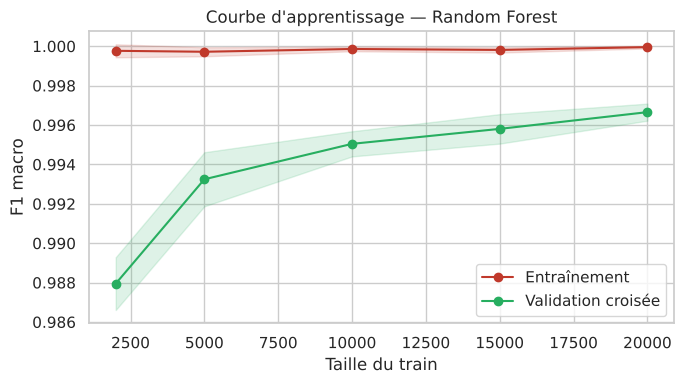

In [6]:
sizes, tr_sc, va_sc = learning_curve(make_pipe(best_strategy, **best_params), Xs.iloc[:30000], ys[:30000], cv=cv, scoring="f1_macro",
                                     train_sizes=[.1, .25, .5, .75, 1.0], n_jobs=1, random_state=RS)
fig, ax = plt.subplots(figsize=(7, 4))
for sc, lab, c in [(tr_sc, "Entraînement", "#c0392b"), (va_sc, "Validation croisée", "#27ae60")]:
    ax.plot(sizes, sc.mean(1), "o-", label=lab, color=c); ax.fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), alpha=.15, color=c)
ax.set(xlabel="Taille du train", ylabel="F1 macro", title="Courbe d'apprentissage — Random Forest"); ax.legend(); plt.tight_layout(); U.savefig(fig, "02_learning_curve"); plt.show()

## 6. Modèle final et évaluation en validation
Réapprentissage sur **tout le train** avec la stratégie et les hyper-paramètres retenus.

Temps d'entraînement : 99.6s
F1 train = 0.9999 | F1 validation = 0.9990
              precision    recall  f1-score   support

      normal     0.9965    0.9964    0.9965      8387
    anomalie     0.9989    0.9990    0.9990     28324

    accuracy                         0.9984     36711
   macro avg     0.9977    0.9977    0.9977     36711
weighted avg     0.9984    0.9984    0.9984     36711



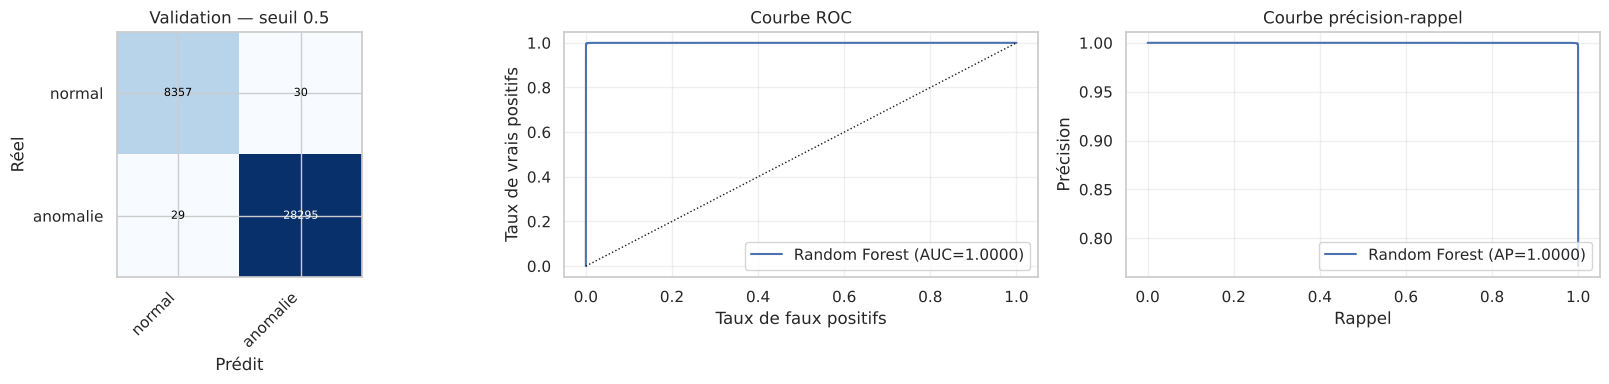

In [7]:
t0 = time.time(); final = make_pipe(best_strategy, **best_params).fit(X_train, ytr); t_fit = time.time() - t0
p_tr, p_va = final.predict_proba(X_train)[:, 1], final.predict_proba(X_valid)[:, 1]
print(f"Temps d'entraînement : {t_fit:.1f}s")
print(f"F1 train = {U.binary_metrics(ytr, (p_tr>=.5).astype(int))['f1']:.4f} | F1 validation = {U.binary_metrics(yva, (p_va>=.5).astype(int))['f1']:.4f}")
print(classification_report(yva, (p_va >= .5).astype(int), target_names=["normal", "anomalie"], digits=4))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
U.plot_confusion(confusion_matrix(yva, (p_va >= .5).astype(int)), ["normal", "anomalie"], "Validation — seuil 0.5", ax=axes[0])
U.plot_roc_pr(yva, p_va, "Random Forest", axes=axes[1:]); plt.tight_layout(); U.savefig(fig, "02_valid_eval"); plt.show()

## 7. Calibration

La demande porte sur la **cible binaire** : on calibre donc deux choses, toujours **sur la validation** (jamais sur le test).

### 7.a Seuil de décision
Le seuil par défaut 0,5 n'est pas optimal. On choisit celui qui maximise le **F1** en validation, puis on l'applique tel quel au test.

Seuil optimal (validation) = 0.4810 — F1 validation = 0.9989


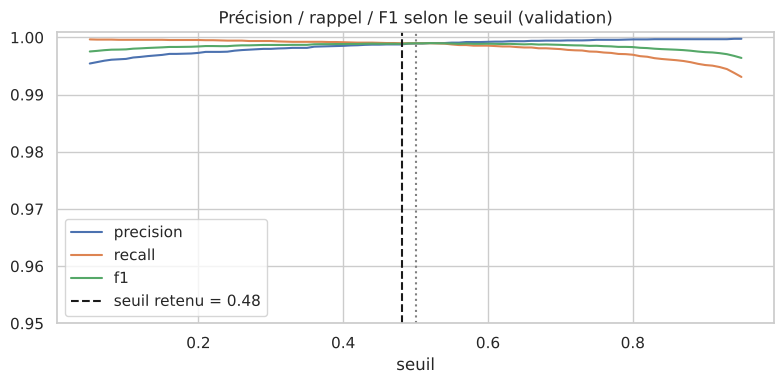

In [8]:
thr, f1_at_thr = U.best_f1_threshold(yva, p_va); print(f"Seuil optimal (validation) = {thr:.4f} — F1 validation = {f1_at_thr:.4f}")
grid = np.linspace(.05, .95, 91)
curve = pd.DataFrame({"seuil": grid, **{m: [fn(yva, (p_va >= t).astype(int), zero_division=0) for t in grid] for m, fn in
         [("precision", U.precision_score), ("recall", U.recall_score), ("f1", U.f1_score)]}})
fig, ax = plt.subplots(figsize=(8, 4)); curve.set_index("seuil").plot(ax=ax); ax.axvline(thr, color="k", ls="--", label=f"seuil retenu = {thr:.2f}"); ax.axvline(.5, color="grey", ls=":")
ax.set(title="Précision / rappel / F1 selon le seuil (validation)", ylim=(.95, 1.001)); ax.legend(); plt.tight_layout(); U.savefig(fig, "02_threshold_curve"); plt.show()

### 7.b Calibration des probabilités
Les probabilités d'un Random Forest sont généralement **sous-confiantes** (aucun arbre ne vote exactement 0 ou 1). On compare le score brut à deux
calibrateurs ajustés sur la validation : **Platt** (régression logistique sur le logit du score) et **isotonique** (fonction monotone par morceaux).
La qualité se mesure avec le **score de Brier** (plus bas = mieux) et le diagramme de fiabilité, sur le **test**.

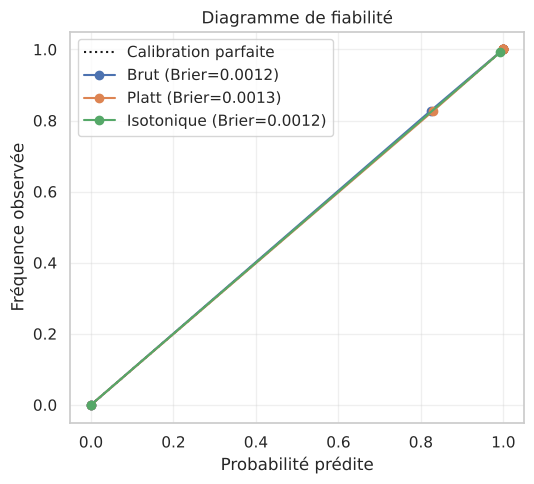

,Brut,Platt,Isotonique
Brier (test),0.0013,0.0013,0.0013


Meilleur calibrateur : Brut


Seuil sur probabilités calibrées (Brut) : 0.4810


In [9]:
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6))).reshape(-1, 1)
platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p_va), yva)
iso = IsotonicRegression(out_of_bounds="clip").fit(p_va, yva)
p_te = final.predict_proba(X_test)[:, 1]
cal_te = {"Brut": p_te, "Platt": platt.predict_proba(logit(p_te))[:, 1], "Isotonique": iso.predict(p_te)}
fig, ax = plt.subplots(figsize=(5.5, 5)); U.plot_calibration(yte, cal_te, ax=ax); plt.tight_layout(); U.savefig(fig, "02_calibration"); plt.show()
brier = pd.Series({k: U.brier_score_loss(yte, v) for k, v in cal_te.items()}, name="Brier (test)"); display(brier.to_frame().T.round(5))
best_cal = brier.idxmin(); print("Meilleur calibrateur :", best_cal)
# seuil recalculé sur les probabilités calibrées de la validation
cal_va = {"Brut": p_va, "Platt": platt.predict_proba(logit(p_va))[:, 1], "Isotonique": iso.predict(p_va)}
thr_cal, _ = U.best_f1_threshold(yva, cal_va[best_cal]); print(f"Seuil sur probabilités calibrées ({best_cal}) : {thr_cal:.4f}")

## 8. Évaluation finale sur le test (une seule fois)
Trois points de fonctionnement sont comparés : seuil par défaut, seuil calibré, seuil sur probabilités calibrées.
Le tableau officiel du notebook 06 utilise la ligne **« seuil calibré »** (choisi uniquement sur la validation).

,accuracy,balanced_accuracy,precision,recall,f1,mcc,fpr,fnr,roc_auc,pr_auc,tn,fp,fn,tp
Seuil 0.5,0.9984,0.9977,0.9989,0.9991,0.9990,0.9956,0.0038,0.0009,1.0000,1.0000,8355.0000,32.0000,25.0000,28299.0000
Seuil calibré (F1 valid),0.9984,0.9976,0.9988,0.9992,0.9990,0.9956,0.0039,0.0008,1.0000,1.0000,8354.0000,33.0000,24.0000,28300.0000
Probas calibrées (Brut),0.9984,0.9976,0.9988,0.9992,0.9990,0.9956,0.0039,0.0008,1.0000,1.0000,8354.0000,33.0000,24.0000,28300.0000


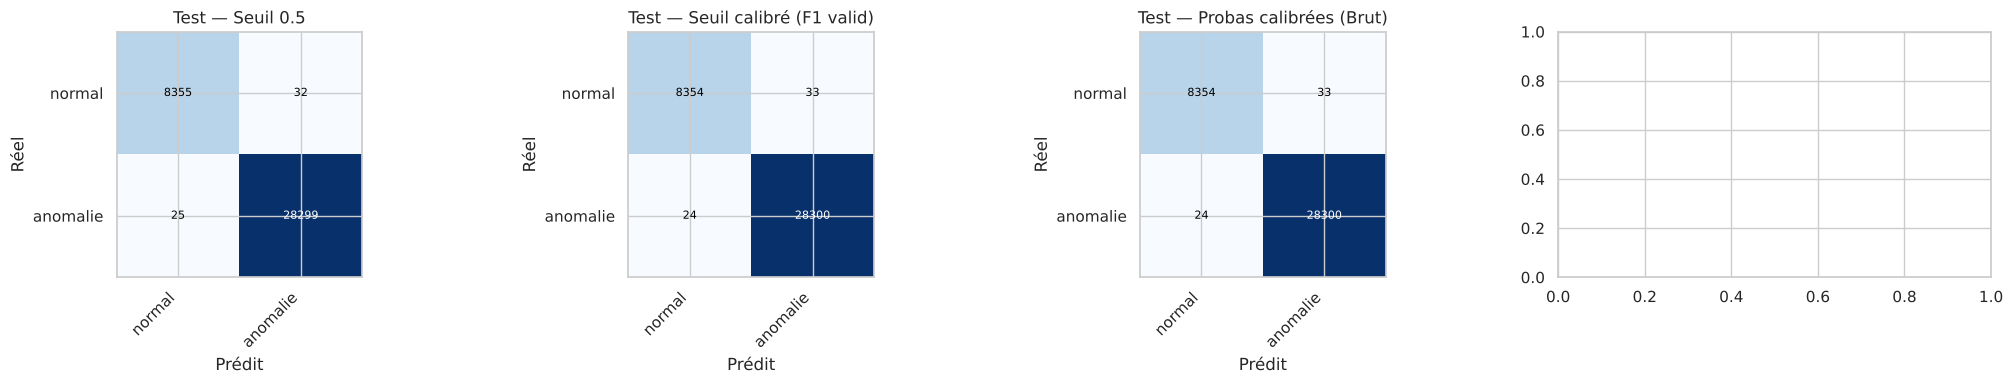

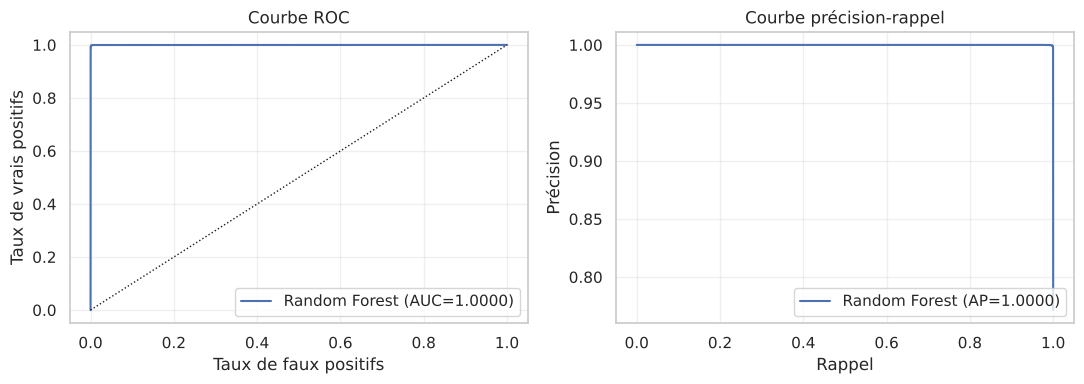

In [10]:
pred = {"Seuil 0.5": (p_te >= .5).astype(int), "Seuil calibré (F1 valid)": (p_te >= thr).astype(int),
        f"Probas calibrées ({best_cal})": (cal_te[best_cal] >= thr_cal).astype(int)}
test_tbl = pd.DataFrame({k: U.binary_metrics(yte, v, scores=p_te, proba=cal_te[best_cal] if "Probas" in k else p_te) for k, v in pred.items()}).T
display(test_tbl[["accuracy", "balanced_accuracy", "precision", "recall", "f1", "mcc", "fpr", "fnr", "roc_auc", "pr_auc", "tn", "fp", "fn", "tp"]].round(4))
fig, axes = plt.subplots(1, 4, figsize=(21, 4))
for ax, (k, v) in zip(axes, pred.items()): U.plot_confusion(confusion_matrix(yte, v), ["normal", "anomalie"], f"Test — {k}", ax=ax)
plt.tight_layout(); U.savefig(fig, "02_test_confusions"); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4)); U.plot_roc_pr(yte, p_te, "Random Forest", axes=axes); plt.tight_layout(); U.savefig(fig, "02_test_roc_pr"); plt.show()

## 9. Interprétation et analyse des erreurs

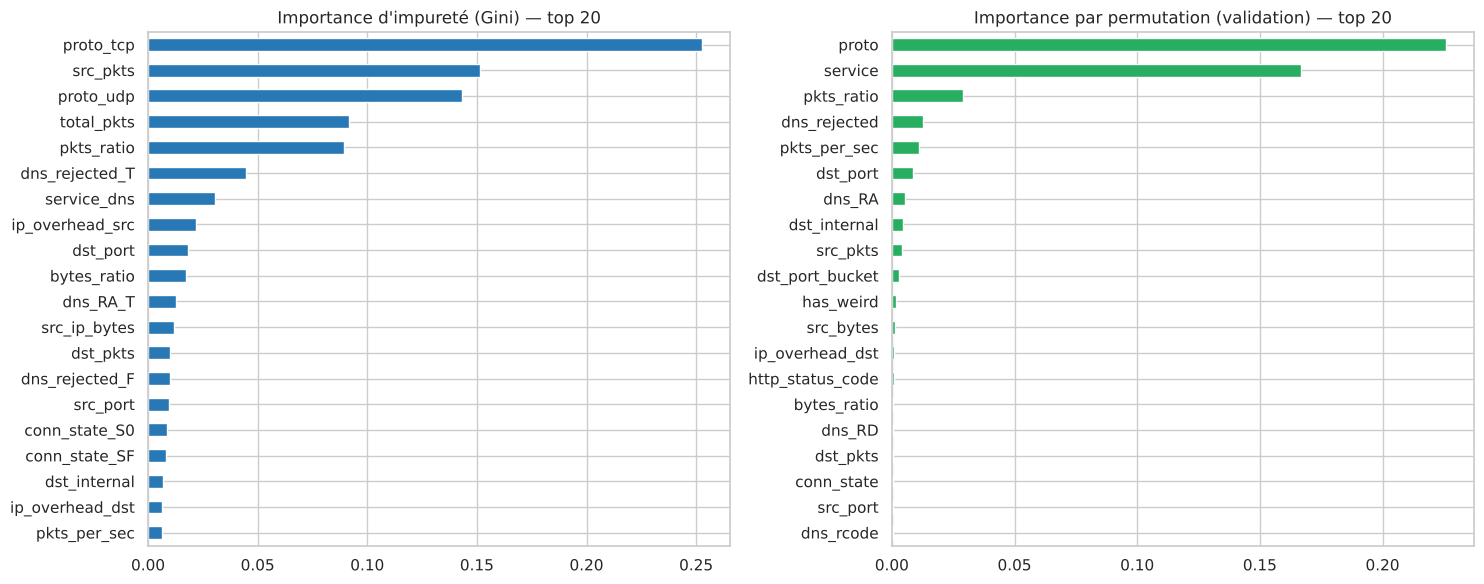

In [11]:
rf_est = final.named_steps["rf"]; names = U.feature_names(final.named_steps["pre"])
imp = pd.Series(rf_est.feature_importances_, index=names).sort_values(ascending=False)
sidx = X_valid.sample(8000, random_state=RS).index
pi = permutation_importance(final, X_valid.loc[sidx], yva[sidx.to_numpy()], scoring="f1_macro", n_repeats=3, random_state=RS, n_jobs=1)
pi_s = pd.Series(pi.importances_mean, index=X_valid.columns).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
imp.head(20).iloc[::-1].plot(kind="barh", ax=axes[0], color="#2878b5"); axes[0].set_title("Importance d'impureté (Gini) — top 20")
pi_s.head(20).iloc[::-1].plot(kind="barh", ax=axes[1], color="#27ae60"); axes[1].set_title("Importance par permutation (validation) — top 20")
plt.tight_layout(); U.savefig(fig, "02_importances"); plt.show()

,n,erreurs,taux_erreur
type,,,
normal,8387,33,0.0039
scanning,3723,1,0.0003
dos,2935,5,0.0017
ddos,3997,16,0.0040
password,3970,0,0.0000
injection,3992,0,0.0000
xss,2904,0,0.0000
backdoor,3742,0,0.0000
ransomware,2853,0,0.0000


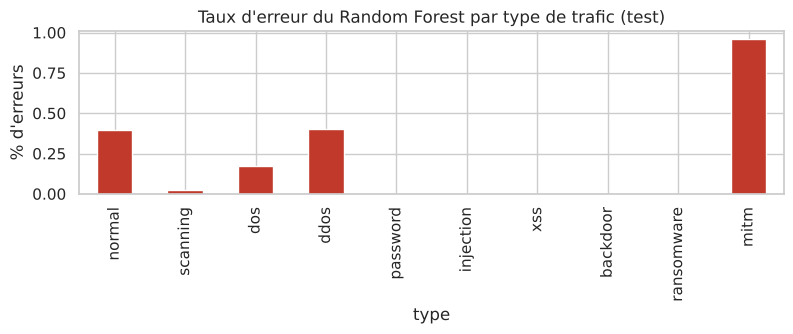

In [12]:
err = pd.DataFrame({"type": y_te["type"].to_numpy(), "label": yte, "pred": pred["Seuil calibré (F1 valid)"]})
err["erreur"] = (err.label != err.pred)
by_type = err.groupby("type").agg(n=("erreur", "size"), erreurs=("erreur", "sum"), taux_erreur=("erreur", "mean")).loc[U.TYPE_ORDER]
display(by_type.round(4))
fig, ax = plt.subplots(figsize=(8, 3.5)); by_type["taux_erreur"].mul(100).plot(kind="bar", ax=ax, color="#c0392b"); ax.set_ylabel("% d'erreurs"); ax.set_title("Taux d'erreur du Random Forest par type de trafic (test)")
plt.tight_layout(); U.savefig(fig, "02_error_by_type"); plt.show()

## 10. Sauvegarde

In [13]:
joblib.dump(final, U.MODEL_DIR / "rf_anomaly.joblib", compress=3)
sel = test_tbl.loc["Seuil calibré (F1 valid)"]
U.save_result("02_rf_anomaly", {
    "task": "Détection d'anomalies", "model": "Random Forest", "balancing": best_strategy, "params": best_params, "threshold": thr,
    "fit_time_s": t_fit, "valid_f1": f1_at_thr, "test": {k: float(v) for k, v in sel.items()},
    "test_default_threshold": {k: float(v) for k, v in test_tbl.loc["Seuil 0.5"].items()}, "brier_test": brier.to_dict(), "balancing_cv": bal.round(5).to_dict("index"),
    "error_by_type": by_type["taux_erreur"].to_dict()})
print("Modèle et résultats sauvegardés.")

Modèle et résultats sauvegardés.


## Conclusion (Random Forest — détection d'anomalies)

Les chiffres exacts figurent dans le tableau du §8 et dans le notebook 06. Ce que les résultats montrent réellement :
- **Équilibrage** : les cinq stratégies sont à ≈ 0,001 de F1 macro les unes des autres, soit le même ordre de grandeur que l'écart-type entre plis (≈ 0,0005). Sur ce jeu, l'équilibrage **change très peu** le résultat ; la stratégie est choisie en CV et documentée, sans prétendre qu'elle soit décisive.
- **Seuil** : le seuil calibré sur la validation (≈ 0,48) est très proche de 0,5 et ne modifie presque pas le test ; le modèle est déjà bien centré.
- **Probabilités** : les probabilités brutes d'un Random Forest sont déjà bien calibrées ici (Brier ≈ 0,0013 pour brut, Platt et isotonique) : la calibration le **confirme** plutôt qu'elle ne corrige.
- **Généralisation** : F1 train ≈ 0,9999 contre ≈ 0,999 en validation et test : léger surapprentissage mais résultat stable entre validation et test.
- **Erreurs** (§9) : concentrées sur le trafic *normal* classé à tort en attaque (faux positifs), puis `ddos`, `dos` et `mitm` ; les autres attaques sont quasiment toutes détectées.
- Scores ≈ 99,9 % : ce jeu est **très séparable** (trafic de banc d'essai scripté). La déduplication ne les a pas fait baisser pour le Random Forest, mais elle garantit qu'aucune ligne identique n'est partagée entre train et test.